In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [15]:
df = pd.read_csv("data/concentrations.csv")
df.head()

,C [ppm]
0,6.251422
1,0.071689
2,0.043338
3,524.708400
4,0.024828


In [21]:
df.describe()


,C [ppm]
count,6000.000000
mean,100.551892
std,227.605011
min,0.001004
25%,0.054426
50%,0.989193
75%,51.636625
max,999.188500


In [22]:
df.isna().sum()


C [ppm]    0
dtype: int64

<Axes: xlabel='C [ppm]', ylabel='Count'>

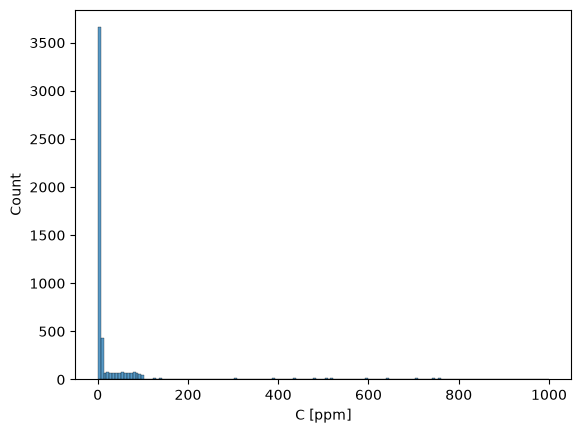

In [24]:
sns.histplot(df['C [ppm]'])

In [30]:
bins = [0, 0.01 , 0.1, 0.5, 1, 5, 10, 20, 50, 100, 200, 500, 1000]
labels = [
    "0–0.01",
    "0.01-0.1",
    "0.1–0.5",
    "0.5–1",
    "1–5",
    "5–10",
    "10–20",
    "20–50",
    "50–100",
    "100–200",
    "200–500",
    "500–1000"
]
df_new = df.copy()
df_new["C_interval"] = pd.cut(
    df_new["C [ppm]"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [31]:
counts = df_new["C_interval"].value_counts().sort_index()
print(counts)


C_interval
0–0.01      1038
0.01-0.1     998
0.1–0.5      435
0.5–1        540
1–5          487
5–10         558
10–20        105
20–50        320
50–100       534
100–200       97
200–500      338
500–1000     550
Name: count, dtype: int64


   C_interval  count
0      0–0.01   1038
1    0.01-0.1    998
2     0.1–0.5    435
3       0.5–1    540
4         1–5    487
5        5–10    558
6       10–20    105
7       20–50    320
8      50–100    534
9     100–200     97
10    200–500    338
11   500–1000    550


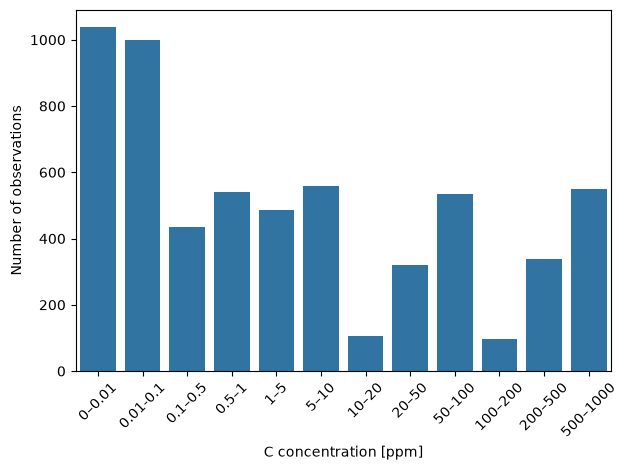

In [40]:
interval_df = (
    df_new["C_interval"]
    .value_counts()
    .sort_index()
    .reset_index()
)
interval_df.columns = ["C_interval", "count"]

print(interval_df)

sns.barplot(
    data=interval_df,
    x="C_interval",
    y="count"
)

plt.xticks(rotation=45)
plt.xlabel("C concentration [ppm]")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

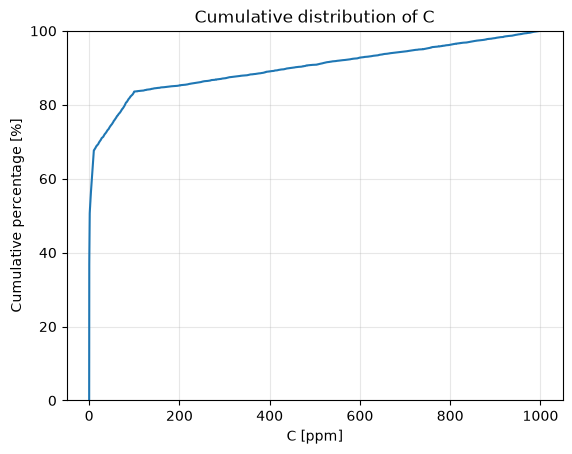

In [43]:
x = np.sort(df["C [ppm]"].dropna())
y = np.arange(1, len(x) + 1) / len(x) * 100

plt.plot(x, y)

plt.xlabel("C [ppm]")
plt.ylabel("Cumulative percentage [%]")
plt.title("Cumulative distribution of C")

plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

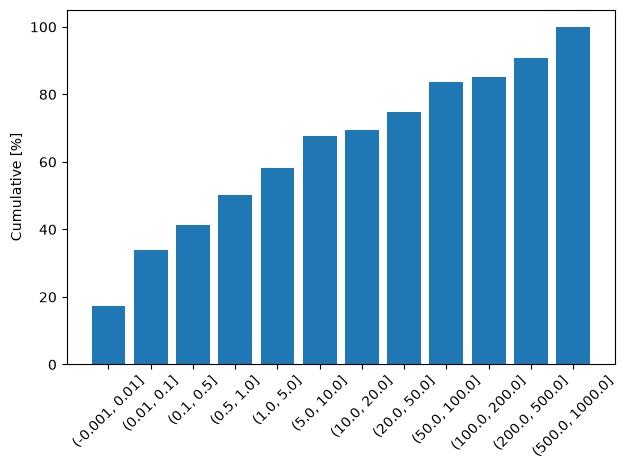

In [44]:
counts = pd.cut(df["C [ppm]"], bins=bins, include_lowest=True).value_counts().sort_index()
cum = counts.cumsum() / counts.sum() * 100

plt.bar(range(len(cum)), cum)
plt.xticks(range(len(cum)), [str(x) for x in cum.index], rotation=45)
plt.ylabel("Cumulative [%]")
plt.tight_layout()
plt.show()


In [61]:
cum

C [ppm]
(-0.001, 0.01]      17.300000
(0.01, 0.1]         33.933333
(0.1, 0.5]          41.183333
(0.5, 1.0]          50.183333
(1.0, 5.0]          58.300000
(5.0, 10.0]         67.600000
(10.0, 20.0]        69.350000
(20.0, 50.0]        74.683333
(50.0, 100.0]       83.583333
(100.0, 200.0]      85.200000
(200.0, 500.0]      90.833333
(500.0, 1000.0]    100.000000
Name: count, dtype: float64